# Regions as islands

A nest shrinks one sample, so the areas it measures are arbitrary: hulls of whichever points remain. `designs.islands` does the other thing: you choose the regions (states, counties, parks, real islands), and each is one row of area and species. That is species-area data of the island type, from the same observations.

In [1]:
import matplotlib.pyplot as plt

import samplesar

plt.rcParams["figure.dpi"] = 80

In [2]:
sample = samplesar.sources.simulated(n_points=1500, seed=3)
sample

Sample(n_observations=3619, n_points=1500, n_species=48, area=6275.91)

## Regions

Regions are named polygons in longitude and latitude. Made-up parks of different sizes here; real ones come from `regions.admin_units` (states, counties) or `regions.read_units` (any boundary file), shown at the end.

In [3]:
from shapely.geometry import box

west, south, east, north = -83.93, 35.25, -83.07, 35.95
parks = {
    "North Fork": box(west, 35.70, -83.50, north),
    "Ridge Top": box(-83.60, 35.50, -83.35, 35.68),
    "Mill Creek": box(-83.30, 35.30, -83.20, 35.38),
    "Big Valley": box(-83.50, south, east, 35.60),
    "Laurel Gap": box(-83.90, 35.30, -83.80, 35.36),
    "East Bench": box(-83.25, 35.70, east, north),
    "Cove": box(-83.75, 35.42, -83.68, 35.47),
}
islands = samplesar.designs.islands(sample, parks)
table = islands.to_frame()
table.round(1)

,region,area,species,n_points,n_observations
0,North Fork,1077.8,9,128,151
1,Ridge Top,452.5,14,65,101
2,Mill Creek,80.7,5,13,32
3,Big Valley,1516.4,22,379,1100
4,Laurel Gap,60.5,1,7,7
5,East Bench,451.2,13,63,138
6,Cove,35.3,6,30,63


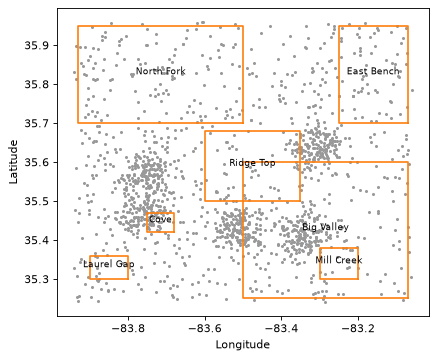

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
points = sample.points
ax.scatter(points[:, 0], points[:, 1], s=3, color="0.6")
for name, park in parks.items():
    ax.plot(*park.exterior.xy, color="C1")
    ax.annotate(name, park.centroid.coords[0], ha="center", fontsize=8)
ax.set(xlabel="Longitude", ylabel="Latitude");

## The island curve

Each region's area is its own, on the ellipsoid, and its species are those observed inside it.

In [5]:
fit = islands.fit("power")
fit.params, float(round(fit.r_squared, 3))

({'c': 0.8221914730783458, 'z': 0.424467876751446}, 0.683)

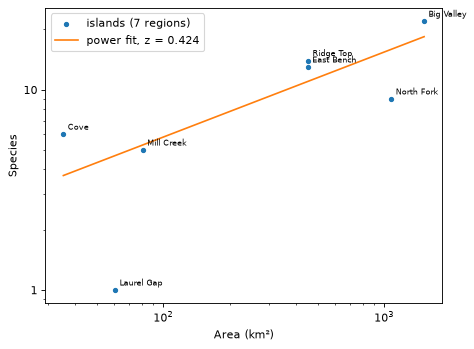

In [6]:
ax = samplesar.plot.curve(islands)
for row in table.itertuples():
    ax.annotate(row.region, (row.area, row.species), fontsize=7, xytext=(4, 4), textcoords="offset points")

## Effort

Regions with more observers have more species recorded, whatever their area. The table carries each region's observations so that effort can be checked before the curve is believed. Here the number of observations tracks species at least as closely as area does:

In [7]:
table[["area", "n_observations", "species"]].corr(method="spearman").round(2)

,area,n_observations,species
area,1.00,0.86,0.79
n_observations,0.86,1.00,0.86
species,0.79,0.86,1.00


Regions without observations are left out of fits by default: in observation data an empty region is more often unvisited than without species. `min_observations` raises that bar.

In [8]:
islands.sar_data(min_observations=50)

,area,species
0,1077.819553,9
1,452.488917,14
2,1516.379519,22
3,451.180278,13
4,35.256092,6


## Against a nest of the same observations

The two designs answer different questions. A nest's steps share their points and its areas come from the observations; regions are separate units with areas of their own. Their curves aren't comparable point for point.

In [9]:
nest = samplesar.strategies.hull_peel(sample)
float(round(fit.params["z"], 3)), float(round(nest.fit("power").params["z"], 3))   # islands, nested

(0.424, 0.394)

## Nesting within a region

`sample_of` gives one region's observations, with areas measured within the region, ready for any strategy.

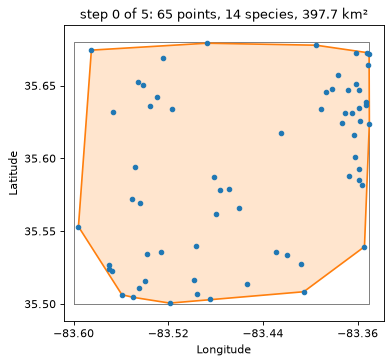

In [10]:
ridge = islands.sample_of("Ridge Top")
samplesar.plot.nest(samplesar.strategies.hull_peel(ridge));

## Real regions

```python
states = samplesar.regions.admin_units("USA", level=1)                 # every state
tennessee = samplesar.regions.admin("USA", 1, "Tennessee")
counties = samplesar.regions.admin_units("USA", 2, inside=tennessee)    # Tennessee's counties
parks = samplesar.regions.read_units("protected_areas.gpkg", "UNIT_NAME")

islands = samplesar.designs.islands(sample, counties, mask=land)        # areas on land only
```

Boundaries from geoBoundaries are downloaded once and cached; they carry their own licenses and need attribution when published.